# 1. Project Introduction
## Zalima: Financial Transaction Fraud Detection
This is a reconstruction of an internship learning project, not the exact original notebook. We compare understandable classifiers using the real Kaggle credit card dataset. No scores or statistics are pre-filled. Run all cells in order after completing the README setup.

# 2. Problem Statement
Identify potentially fraudulent transactions (Class = 1). Missing fraud and investigating legitimate transactions both carry costs. Average precision (AP) is our model-selection metric; precision, recall and F1 explain the decisions at a fixed threshold of 0.5. Accuracy would obscure minority-class performance.

# 3. Dataset Description
Use [Kaggle's original dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Time is elapsed time, Amount is the transaction amount, and V1–V28 are anonymised PCA features. Class is the label. Compute all dataset statistics below rather than assuming published counts. These features cannot be reconstructed from arbitrary raw card details.

Exact duplicate rows will be removed before splitting so identical records do not cross partitions. This may remove genuine repeated transactions; the choice and count are reported. A random stratified split is a foundational benchmark, not a simulation of future deployment. Time-based evaluation is a future improvement.

# 4. Importing Libraries
The repository root is detected whether Jupyter starts here or in notebooks/. A fixed seed makes the split and estimators reproducible. Only two XGBoost threads and sequential cross-validation limit laptop resource use.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
from datetime import datetime, timezone
from importlib.metadata import version

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, RocCurveDisplay)
from xgboost import XGBClassifier

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'predict.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'predict.py').is_file():
    raise RuntimeError('Start Jupyter from the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT))
from src.predict import FEATURES, validate_features, predict_transactions

SEED = 42
DATA_PATH = ROOT / 'data' / 'creditcard.csv'
sns.set_theme(style='whitegrid')

# 5. Data Loading
Inspect before cleaning. Reject missing targets, unexpected schema, invalid class labels, infinite values and entirely missing feature columns. Median imputation later handles missing feature values without using the test set. Never silently sample or fabricate data.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError('Download creditcard.csv from Kaggle into data/. See README.md.')
raw = pd.read_csv(DATA_PATH)
print('Raw dimensions:', raw.shape)
display(raw.dtypes.rename('dtype').to_frame())
display(raw.isna().sum().rename('missing').to_frame())
duplicate_count = int(raw.duplicated().sum())
print('Exact duplicate rows:', duplicate_count)
if set(raw.columns) != set(FEATURES + ['Class']) or raw.columns.duplicated().any():
    raise ValueError('Expected exactly Time, V1–V28, Amount and Class.')
if raw['Class'].isna().any() or set(raw['Class'].unique()) != {0, 1}:
    raise ValueError('Class must contain both 0 and 1, with no missing targets.')
clean = raw.drop_duplicates().reset_index(drop=True)
X = validate_features(clean.drop(columns='Class'))
y = clean['Class'].astype(int)
if X.isna().all().any():
    raise ValueError('An entire feature column is missing.')
print('Dimensions after deduplication:', clean.shape)
display(y.value_counts().sort_index().rename_axis('Class').to_frame('count'))

Raw dimensions: (284807, 31)


,dtype
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


,missing
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Exact duplicate rows: 1081


Dimensions after deduplication: (283726, 31)


,count
Class,
0,283253
1,473


# 6. Exploratory Data Analysis
Reserve the test set before examining transaction patterns. The following distributions describe training data only, to keep feature and model choices independent of held-out test values. A logarithmic count axis makes the minority class visible.

,count,mean,std,min,25%,50%,75%,max
Time,226980.0,94900.224390,47488.214282,0.000000,54241.750000,84816.000000,139364.250000,172792.000000
V1,226980.0,0.005027,1.947293,-56.407510,-0.915886,0.018358,1.315404,2.454930
V2,226980.0,-0.005549,1.649617,-72.715728,-0.601108,0.063820,0.801327,22.057729
V3,226980.0,0.002131,1.507270,-33.680984,-0.887261,0.178307,1.027460,9.382558
V4,226980.0,-0.002025,1.416960,-5.683171,-0.849272,-0.021999,0.741399,16.875344
V5,226980.0,0.004941,1.359643,-32.092129,-0.689146,-0.052477,0.615362,34.801666
V6,226980.0,-0.001961,1.323401,-26.160506,-0.768760,-0.275923,0.397381,21.393069
V7,226980.0,0.001480,1.200181,-43.557242,-0.552497,0.040832,0.571905,34.303177
V8,226980.0,-0.000215,1.169342,-73.216718,-0.208633,0.022232,0.325467,20.007208
V9,226980.0,-0.002883,1.094055,-13.434066,-0.644309,-0.052811,0.594205,15.594995


Class
0    0.998335
1    0.001665
Name: training proportion, dtype: float64

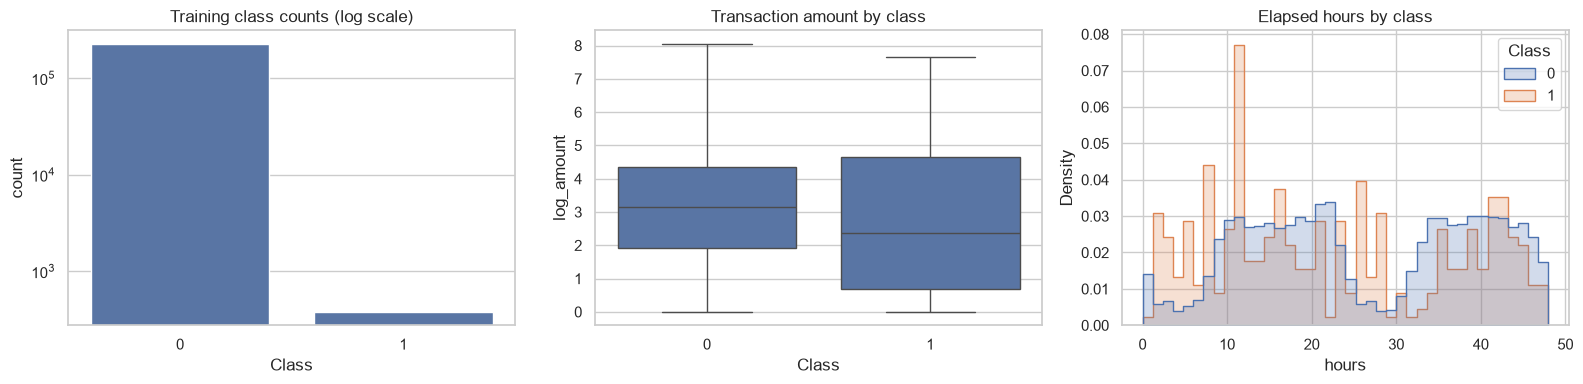

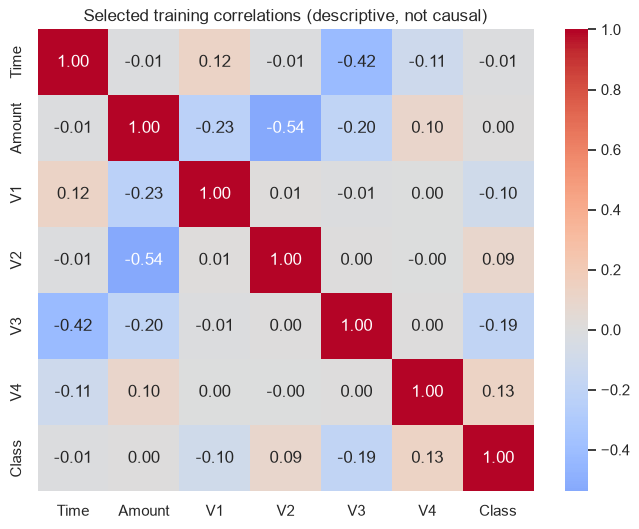

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
if y_train.value_counts().min() < 3 or y_test.nunique() != 2:
    raise ValueError('Not enough minority examples for three-fold CV and a two-class test set.')
if X_train.isna().all().any():
    raise ValueError('A training feature is entirely missing; inspect the dataset.')
eda = X_train.assign(Class=y_train)
display(X_train.describe().T)
display(y_train.value_counts(normalize=True).sort_index().rename('training proportion'))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=eda, x='Class', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Training class counts (log scale)')
sns.boxplot(data=eda.assign(log_amount=np.log1p(eda['Amount'])), x='Class', y='log_amount', ax=axes[1], showfliers=False)
axes[1].set_title('Transaction amount by class')
sns.histplot(data=eda.assign(hours=eda['Time'] / 3600), x='hours', hue='Class',
             element='step', stat='density', common_norm=False, bins=40, ax=axes[2])
axes[2].set_title('Elapsed hours by class')
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 6))
sns.heatmap(eda[['Time', 'Amount', 'V1', 'V2', 'V3', 'V4', 'Class']].corr(),
            annot=True, fmt='.2f', center=0, cmap='coolwarm')
plt.title('Selected training correlations (descriptive, not causal)')
plt.show()

# 7. Data Preprocessing
Every estimator sits inside a scikit-learn Pipeline. Median imputation is fitted separately inside each cross-validation training fold, and later on all training rows. Scaling is also fitted inside the logistic regression pipeline; trees do not require it. No feature selection is based on the test data.

In [4]:
def make_pipeline(classifier, scale=False):
    steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True))]
    if scale:
        steps.append(('scaler', StandardScaler()))
    steps.append(('classifier', classifier))
    return Pipeline(steps)

# 8. Feature Preparation
All 30 available features are retained in a fixed order. Labels are never included in prediction inputs. The reusable validator reorders named inputs and rejects unexpected columns, negative Time/Amount and infinite values.

In [5]:
X_train = X_train.loc[:, FEATURES]
X_test = X_test.loc[:, FEATURES]
print('Training rows:', len(X_train), 'Test rows:', len(X_test))
print('Features:', FEATURES)

Training rows: 226980 Test rows: 56746
Features: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


# 9. Handling Class Imbalance
Use class weighting rather than synthetic oversampling. Logistic regression and the tree compute balanced class weights from each fit's labels. XGBoost receives balanced sample weights computed inside each fit, including each CV fold; thus validation labels never determine training weights. No SMOTE or resampling touches the test set.

In [6]:
from src.training import FoldBalancedXGBClassifier

models = {
    'Logistic Regression': make_pipeline(LogisticRegression(
        class_weight='balanced', max_iter=2000, random_state=SEED), scale=True),
    'Decision Tree': make_pipeline(DecisionTreeClassifier(
        class_weight='balanced', max_depth=6, min_samples_leaf=10, random_state=SEED)),
    'XGBoost': make_pipeline(FoldBalancedXGBClassifier(
        n_estimators=150, max_depth=3, learning_rate=0.1,
        tree_method='hist', eval_metric='logloss', n_jobs=2, random_state=SEED)),
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# 10. Model Training
Compare three baseline pipelines using only the training partition. Each pipeline is refitted inside each fold. Three folds keep the exercise modest; the full dataset can still take several minutes on a laptop. Warnings about convergence should be investigated, not suppressed.

In [7]:
scoring = {'ap': 'average_precision', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}
cv_rows = []
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                            scoring=scoring, n_jobs=1, error_score='raise')
    row = {'model': name}
    for metric in scoring:
        row[metric] = float(scores['test_' + metric].mean())
    row['ap_std'] = float(scores['test_ap'].std())
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows).set_index('model').sort_values('ap', ascending=False)
display(cv_results)

,ap,roc_auc,precision,recall,f1,ap_std
model,,,,,,
XGBoost,0.805741,0.980044,0.467181,0.867725,0.606993,0.014061
Logistic Regression,0.754311,0.982361,0.059602,0.917989,0.111838,0.022035
Decision Tree,0.446296,0.864303,0.103283,0.822751,0.182065,0.150593


# 11. Model Evaluation
Define the evaluation function here, but defer test evaluation until model selection is fixed. Average precision summarises the precision–recall curve without trapezoidal interpolation and is reported as PR average precision. ROC-AUC measures ranking across false-positive rates; AP is particularly useful with rare positives. Confusion matrices expose the actual investigation burden.

In [8]:
def evaluate(pipeline, features, target):
    score = pipeline.predict_proba(features)[:, 1]
    predicted = (score >= 0.5).astype(int)
    return {
        'precision': float(precision_score(target, predicted, zero_division=0)),
        'recall': float(recall_score(target, predicted, zero_division=0)),
        'f1': float(f1_score(target, predicted, zero_division=0)),
        'roc_auc': float(roc_auc_score(target, score)),
        'average_precision': float(average_precision_score(target, score)),
        'confusion_matrix': confusion_matrix(target, predicted, labels=[0, 1]).tolist(),
    }

# 12. Model Comparison
Select the leading baseline by mean cross-validation AP, not by test performance. AP variability helps reveal unstable rankings. Logistic regression offers a simpler linear baseline; a tree is easy to inspect; XGBoost models richer interactions. Suitability depends on measured performance, investigation capacity and interpretability, not the model's name.

Leading baseline by training CV average precision: XGBoost


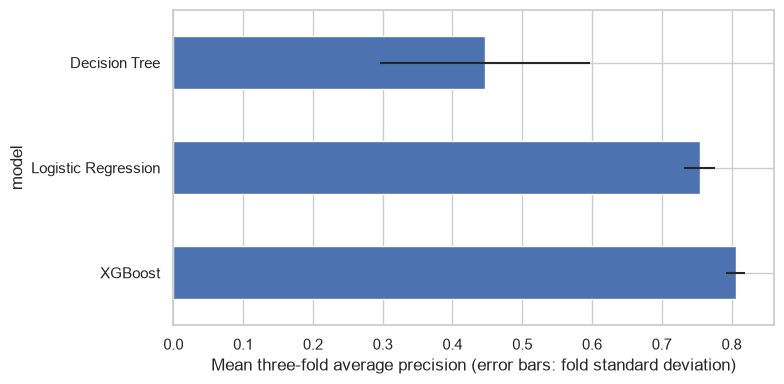

In [9]:
leader = cv_results.index[0]
print('Leading baseline by training CV average precision:', leader)
cv_results['ap'].plot.barh(xerr=cv_results['ap_std'], figsize=(8, 4))
plt.xlabel('Mean three-fold average precision (error bars: fold standard deviation)')
plt.tight_layout()
plt.show()

# 13. Hyperparameter Tuning
Tune only the leading family with a four-configuration GridSearchCV (12 fold fits plus refit). This focused search uses average precision and the same training-only folds. Comparing and tuning on these folds can make CV scores optimistic; the untouched test split gives the final check. We do not optimise the decision threshold on the test set.

In [10]:
grids = {
    'Logistic Regression': {'classifier__C': [0.01, 0.1, 1.0, 10.0]},
    'Decision Tree': {'classifier__max_depth': [4, 8], 'classifier__min_samples_leaf': [10, 30]},
    'XGBoost': {'classifier__max_depth': [3, 5], 'classifier__learning_rate': [0.05, 0.1]},
}
search = GridSearchCV(models[leader], grids[leader], scoring='average_precision',
                      cv=cv, n_jobs=1, error_score='raise', refit=True)
search.fit(X_train, y_train)
display(pd.DataFrame(search.cv_results_)[['params', 'mean_test_score', 'std_test_score']])
print('Best parameters:', search.best_params_)

,params,mean_test_score,std_test_score
0,"{'classifier__learning_rate': 0.05, 'classifie...",0.758455,0.021517
1,"{'classifier__learning_rate': 0.05, 'classifie...",0.817578,0.016306
2,"{'classifier__learning_rate': 0.1, 'classifier...",0.805741,0.014061
3,"{'classifier__learning_rate': 0.1, 'classifier...",0.848038,0.028399


Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 5}


# 14. Final Model Selection
Retain the leading baseline if tuning fails to improve mean CV AP. Freeze that choice before looking at test metrics. Fit the baseline models on the entire training partition and evaluate them once for a descriptive held-out comparison. Do not switch the selected model after seeing this table.

The XGBoost weighting estimator lives in src/training.py so the saved pipeline can be loaded from the CLI or app without notebook definitions. The repository must remain available on the Python import path.

,precision,recall,f1,roc_auc,average_precision,confusion_matrix
model,,,,,,
Logistic Regression (baseline),0.056386,0.873684,0.105935,0.965655,0.671924,"[[55262, 1389], [12, 83]]"
Decision Tree (baseline),0.067986,0.831579,0.125696,0.914839,0.472853,"[[55568, 1083], [16, 79]]"
XGBoost (baseline),0.330612,0.852632,0.476471,0.969478,0.753629,"[[56487, 164], [14, 81]]"
XGBoost (selected tuned),0.817204,0.800000,0.808511,0.976379,0.809904,"[[56634, 17], [19, 76]]"


Selected XGBoost (tuned) from training CV AP=0.848038.
Test results describe this fixed choice; they do not drive another round of tuning.


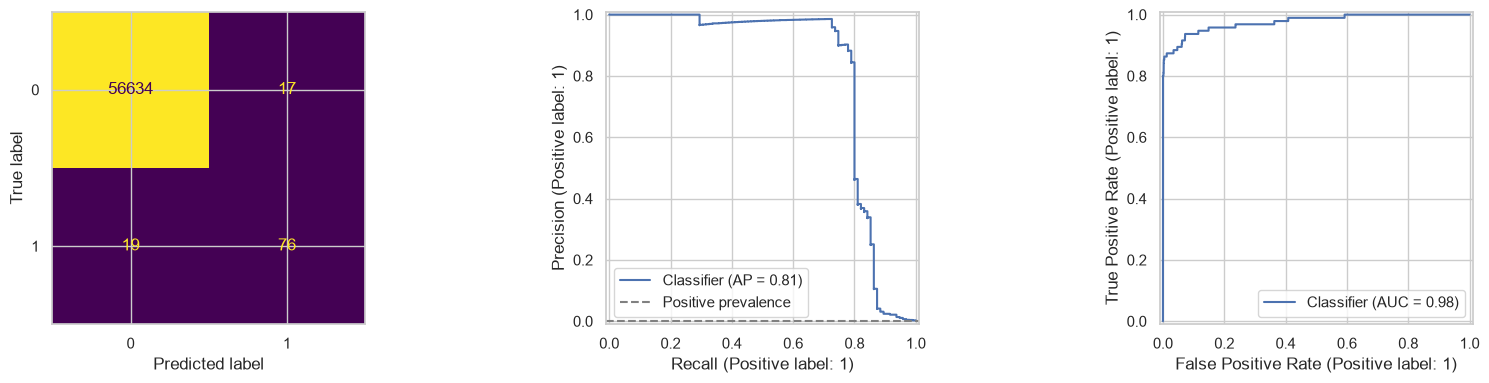

Saved pipeline and actual run reports.


In [11]:
selected_name = leader
if search.best_score_ >= cv_results.loc[leader, 'ap']:
    final_model = search.best_estimator_
    selected_cv_ap = float(search.best_score_)
    selection = 'tuned'
else:
    final_model = clone(models[leader]).fit(X_train, y_train)
    selected_cv_ap = float(cv_results.loc[leader, 'ap'])
    selection = 'baseline'

test_rows = []
for name, baseline in models.items():
    fitted = clone(baseline).fit(X_train, y_train)
    metrics = evaluate(fitted, X_test, y_test)
    test_rows.append({'model': name + ' (baseline)', **metrics})
final_metrics = evaluate(final_model, X_test, y_test)
test_rows.append({'model': selected_name + ' (selected ' + selection + ')', **final_metrics})
test_results = pd.DataFrame(test_rows).set_index('model')
display(test_results)
print(f'Selected {selected_name} ({selection}) from training CV AP={selected_cv_ap:.6f}.')
print('Test results describe this fixed choice; they do not drive another round of tuning.')

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
score = final_model.predict_proba(X_test)[:, 1]
ConfusionMatrixDisplay.from_predictions(y_test, score >= 0.5, labels=[0, 1], ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(y_test, score, ax=axes[1])
RocCurveDisplay.from_predictions(y_test, score, ax=axes[2])
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label='Positive prevalence')
axes[1].legend()
plt.tight_layout()
plt.show()

(ROOT / 'models').mkdir(exist_ok=True)
(ROOT / 'reports').mkdir(exist_ok=True)
model_path = ROOT / 'models' / 'fraud_pipeline.joblib'
joblib.dump(final_model, model_path)
cv_results.to_csv(ROOT / 'reports' / 'cv_comparison.csv')
test_results.to_json(ROOT / 'reports' / 'test_metrics.json', orient='index', indent=2)
hasher = hashlib.sha256()
with DATA_PATH.open('rb') as handle:
    for block in iter(lambda: handle.read(1024 * 1024), b''):
        hasher.update(block)
metadata = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'dataset_sha256': hasher.hexdigest(), 'raw_rows': len(raw),
    'duplicates_removed': duplicate_count, 'train_rows': len(X_train), 'test_rows': len(X_test),
    'seed': SEED, 'threshold': 0.5, 'features': FEATURES,
    'selected_model': selected_name, 'selection': selection,
    'cv_average_precision': selected_cv_ap, 'tuning_parameters': search.best_params_,
    'test_metrics': final_metrics,
    'python': sys.version,
    'packages': {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'joblib']},
}
(ROOT / 'reports' / 'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Saved pipeline and actual run reports.')

# 15. Prediction Demonstration
Use an actual held-out row with Class removed. Required input: a DataFrame or CSV containing exactly Time, V1 through V28, and Amount. Column order is normalised by name. Missing values are imputed with the training medians. Scores reflect a weighted classifier and are not calibrated fraud probabilities. The default flag threshold is 0.5.

Load only Joblib files you trust. This reload also checks that the exported model scores identically to the in-memory pipeline.

In [12]:
reloaded = joblib.load(model_path)
example = X_test.iloc[[0]].copy()
np.testing.assert_allclose(final_model.predict_proba(example), reloaded.predict_proba(example))
display(example)
display(predict_transactions(example, reloaded))
print('True held-out label for this demonstration:', int(y_test.iloc[0]))

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
86249,61290.0,1.228821,-0.063408,0.274145,0.647465,-0.048135,0.372073,-0.224231,0.079939,0.640759,...,-0.096566,-0.129554,-0.083779,-0.151661,-0.700372,0.59855,0.491409,0.002989,0.001782,11.5


,fraud_score,prediction
86249,0.000082,0


True held-out label for this demonstration: 0


# 16. Conclusion and Future Improvements
After execution, the tables above and reports/ contain the measured outcomes. The selected model is determined by training CV average precision; precision and recall at threshold 0.5 reveal its operating tradeoff. Read the confusion matrix as [[true negatives, false positives], [false negatives, true positives]]. Explain these actual findings in an interview; do not claim internship scores from an unexecuted reconstruction.

Limitations: anonymised features limit business interpretation; duplicate removal may discard real events; a random split does not establish future performance; the original PCA transformation was supplied by the dataset and cannot be refitted here; class weights change score calibration; AP depends on prevalence; CV selection introduces optimism; fraud patterns can drift. Before real use, evaluate temporal and customer-level separation, calibrate scores and choose thresholds with separate validation data and explicit costs. Consider confidence intervals, drift monitoring and human review.

References: [scikit-learn average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).